# 02 · Results

**Question:** given a user's history of game reviews, which game will they review next?

Every model is scored by the same code (`src/evaluate.py`):

- Each user's **last review is hidden**. The model sees everything before it and ranks all ~35,000 games (minus ones the user already reviewed).
- **Recall@10** = share of users whose hidden game is in the model's top 10.
- **NDCG@10** = like Recall@10, but a hit at rank 1 counts more than a hit at rank 10 (rank 1 → 1.0, rank 10 → 0.29).
- **Core users** have 5+ reviews (1.9M users), **light users** have 2–4 (4.3M users).
- **Play next** counts every hidden review; **enjoy** counts only hidden reviews that are 👍.

Settings were chosen on a separate **validation** review (each core user's second-last review), so the test review was never used for tuning.
This notebook only reads the small CSV files in `results/`, so it runs in seconds.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
FIGURES = ROOT / "docs" / "figures"   # charts reused in the README
FIGURES.mkdir(parents=True, exist_ok=True)

# Display names, and whether the model is told the date of the hidden review ("today")
MODELS = {
    "popularity":          ("Popularity (all-time)",        False),
    "recent_pop_lasthist": ("Recent popularity, last visit", False),
    "als":                 ("ALS",                          False),
    "item_knn":            ("Item-KNN",                     False),
    "sasrec":              ("SASRec",                       False),
    "recent_pop":          ("Recent popularity (yesterday)", True),
    "sasrec_trend":        ("SASRec + trending",            True),
}

results = (
    pl.read_csv(RESULTS / "results.csv")
    .filter(pl.col("stage") == "test", pl.col("model").is_in(list(MODELS)))
    .with_columns(
        pl.col("model").replace_strict({k: v[0] for k, v in MODELS.items()}).alias("name"),
        pl.col("model").replace_strict({k: v[1] for k, v in MODELS.items()}).alias("knows_date"),
    )
)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Leaderboard (test set, play next)

Two models are told the date of the hidden review, standing in for "today" when a user opens the app.
A live system always knows today's date, but it is extra information the other models did not get, so they are marked separately.

In [2]:
board = (
    results.filter(pl.col("target") == "play_next")
    .pivot(on="users", index=["name", "knows_date"], values=["recall@10", "ndcg@10"])
    .select(
        "name", "knows_date",
        pl.col("recall@10_core").alias("recall_core"), pl.col("recall@10_light").alias("recall_light"),
        pl.col("recall@10_all_users").alias("recall_all"),
        pl.col("ndcg@10_core").alias("ndcg_core"), pl.col("ndcg@10_light").alias("ndcg_light"),
    )
    .sort("recall_core")
)
with pl.Config(float_precision=4, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True, tbl_width_chars=160, fmt_str_lengths=40):
    display(board.sort("recall_core", descending=True))

name,knows_date,recall_core,recall_light,recall_all,ndcg_core,ndcg_light
"""SASRec + trending""",true,0.2351,0.2144,0.2208,0.1514,0.1335
"""Recent popularity (yesterday)""",true,0.1757,0.1782,0.1774,0.1135,0.1126
"""SASRec""",false,0.1705,0.1432,0.1516,0.0953,0.0781
"""Item-KNN""",false,0.0935,0.1057,0.1020,0.0500,0.0589
"""ALS""",false,0.0857,0.1002,0.0957,0.0447,0.0563
"""Recent popularity, last visit""",false,0.0376,0.0414,0.0402,0.0189,0.0195
"""Popularity (all-time)""",false,0.0342,0.0511,0.0459,0.0174,0.0246


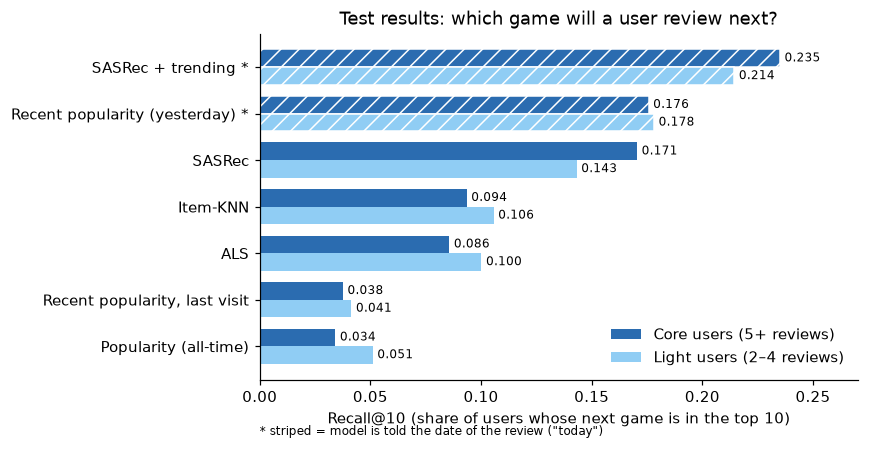

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(board.height)
h = 0.38
for offset, col, label, color in [(h / 2, "recall_core", "Core users (5+ reviews)", "#2b6cb0"),
                                  (-h / 2, "recall_light", "Light users (2–4 reviews)", "#90cdf4")]:
    bars = ax.barh([i + offset for i in y], board[col], height=h, label=label, color=color)
    for bar, knows in zip(bars, board["knows_date"]):
        if knows:
            bar.set_hatch("//")
            bar.set_edgecolor("white")
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.set_yticks(list(y), [n + (" *" if k else "") for n, k in zip(board["name"], board["knows_date"])])
ax.set_xlabel("Recall@10 (share of users whose next game is in the top 10)")
ax.set_title("Test results: which game will a user review next?")
ax.legend(loc="lower right", frameon=False)
ax.text(0, -0.16, "* striped = model is told the date of the review (\"today\")", transform=ax.transAxes, fontsize=8)
ax.set_xlim(0, board["recall_core"].max() * 1.15)
plt.tight_layout()
plt.savefig(FIGURES / "leaderboard.png", bbox_inches="tight")
plt.show()

**Reading the chart**

- **Personal models beat all-time popularity by 2–5×**, but that is an easy target: all-time popularity ignores *when* a user reviews.
- **Recent popularity is the strong baseline.** Recommending whatever was reviewed most *yesterday* reaches 0.176 for core users, slightly above SASRec, without knowing anything about the user. Which game someone reviews next is driven heavily by what everyone is playing right now (launches, sales, free weekends).
- **SASRec gets close without the date.** It only reads the order of a user's past games, yet nearly matches the date-aware baseline.
- **SASRec + trending is best for both groups** (0.235 core, 0.214 light): +34% over recent popularity and +38% over SASRec for core users. Personal history adds value on top of trends.
- **Core vs light:** the item-based models (KNN, ALS) do slightly *better* on light users, whose few reviews are often of very popular games. SASRec does better on core users, because a longer sequence gives it more to read.

## 3. Play next vs enjoy

Does the model find games the user goes on to *like* (👍), or just games they review?

name,play_next,enjoy,enjoy_vs_play
"""SASRec + trending""",0.2351,0.2251,-0.0425
"""Recent popularity (yesterday)""",0.1757,0.1605,-0.0866
"""SASRec""",0.1705,0.1673,-0.0189
"""Item-KNN""",0.0935,0.0974,0.0415
"""ALS""",0.0857,0.0872,0.0183
"""Recent popularity, last visit""",0.0376,0.0368,-0.0204
"""Popularity (all-time)""",0.0342,0.0340,-0.0046


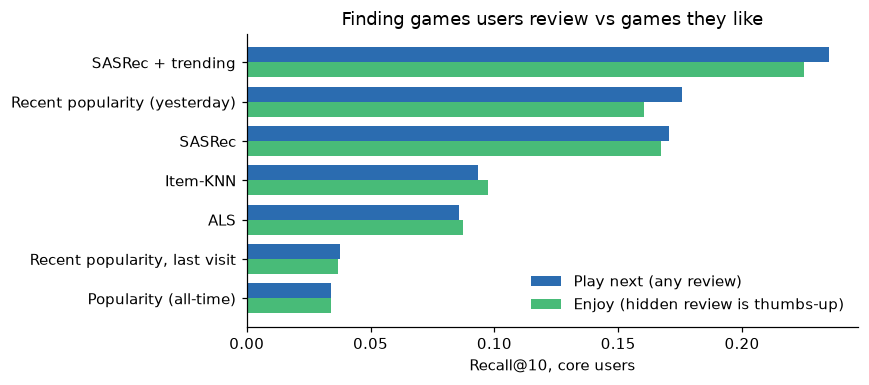

In [4]:
pe = (
    results.filter(pl.col("users") == "core")
    .pivot(on="target", index="name", values="recall@10")
    .join(board.select("name", "recall_core"), on="name")
    .sort("recall_core")
    .with_columns((pl.col("enjoy") / pl.col("play_next") - 1).alias("enjoy_vs_play"))
)
with pl.Config(float_precision=4, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True, tbl_width_chars=160, fmt_str_lengths=40):
    display(pe.select("name", "play_next", "enjoy", "enjoy_vs_play").sort("play_next", descending=True))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(pe.height)
ax.barh([i + 0.19 for i in y], pe["play_next"], height=0.38, label="Play next (any review)", color="#2b6cb0")
ax.barh([i - 0.19 for i in y], pe["enjoy"], height=0.38, label="Enjoy (hidden review is thumbs-up)", color="#48bb78")
ax.set_yticks(list(y), pe["name"])
ax.set_xlabel("Recall@10, core users")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Finding games users review vs games they like")
plt.tight_layout()
plt.show()

- For **item-KNN and ALS**, enjoy is a little *higher* than play next: games similar to what a user already reviewed tend to be ones they like.
- For **recent popularity**, enjoy is ~9% *lower*: trending games attract people who try them because of the hype and then give a 👎.
- The scores measure **"next game reviewed"**, not enjoyment. 84% of hidden reviews are 👍, so the two are close, but the gap above shows they are not the same thing.

## 4. How each model was tuned (validation set, 100k core users)

Each model's settings were picked on the validation review. Charts show Recall@10.

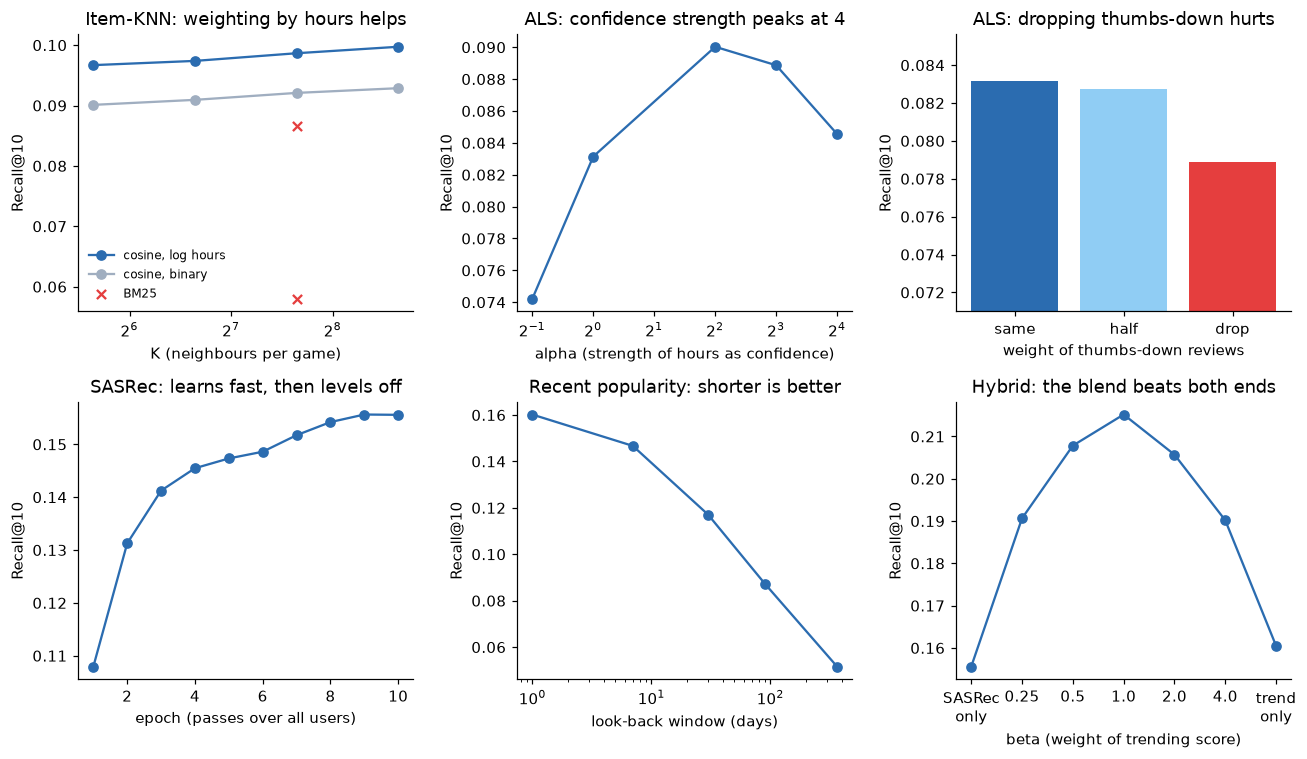

In [5]:
knn = pl.read_csv(RESULTS / "knn_tuning.csv")
als = pl.read_csv(RESULTS / "als_tuning.csv")
sas = pl.read_csv(RESULTS / "sasrec_tuning.csv")
rp = pl.read_csv(RESULTS / "recent_pop_tuning.csv").filter(pl.col("anchor") == "target").sort("window_days")
hy = pl.read_csv(RESULTS / "sasrec_trend_tuning.csv").filter(pl.col("window_days") == 1).sort("beta")

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

ax = axes[0, 0]
for weighting, color in [("log_hours", "#2b6cb0"), ("binary", "#a0aec0")]:
    d = knn.filter((pl.col("similarity") == "cosine") & (pl.col("weighting") == weighting)).sort("k")
    ax.plot(d["k"], d["recall@10"], marker="o", color=color, label=f"cosine, {weighting.replace('_', ' ')}")
bm = knn.filter(pl.col("similarity") == "bm25")
ax.scatter(bm["k"], bm["recall@10"], marker="x", color="#e53e3e", label="BM25")
ax.set_xscale("log", base=2); ax.set_xlabel("K (neighbours per game)")
ax.set_title("Item-KNN: weighting by hours helps"); ax.legend(frameon=False, fontsize=8)

ax = axes[0, 1]
d = als.filter((pl.col("factors") == 64) & (pl.col("regularization") == 0.05) & (pl.col("negatives") == "same")).sort("alpha")
ax.plot(d["alpha"], d["recall@10"], marker="o", color="#2b6cb0")
ax.set_xscale("log", base=2); ax.set_xlabel("alpha (strength of hours as confidence)")
ax.set_title("ALS: confidence strength peaks at 4")

ax = axes[0, 2]
d = als.filter((pl.col("factors") == 64) & (pl.col("regularization") == 0.05) & (pl.col("alpha") == 1.0))
d = d.sort(pl.col("negatives").replace_strict({"same": 0, "half": 1, "drop": 2}))
ax.bar(d["negatives"], d["recall@10"], color=["#2b6cb0", "#90cdf4", "#e53e3e"])
ax.set_ylim(d["recall@10"].min() * 0.9, d["recall@10"].max() * 1.03)
ax.set_xlabel("weight of thumbs-down reviews"); ax.set_title("ALS: dropping thumbs-down hurts")

ax = axes[1, 0]
ax.plot(sas["epoch"], sas["recall@10"], marker="o", color="#2b6cb0")
ax.set_xlabel("epoch (passes over all users)"); ax.set_title("SASRec: learns fast, then levels off")

ax = axes[1, 1]
ax.plot(rp["window_days"], rp["recall@10"], marker="o", color="#2b6cb0")
ax.set_xscale("log"); ax.set_xlabel("look-back window (days)")
ax.set_title("Recent popularity: shorter is better")

ax = axes[1, 2]
x = [str(b) if b < 100 else "trend\nonly" for b in hy["beta"]]
x[0] = "SASRec\nonly"
ax.plot(x, hy["recall@10"], marker="o", color="#2b6cb0")
ax.set_xlabel("beta (weight of trending score)"); ax.set_title("Hybrid: the blend beats both ends")

for ax in axes.flat:
    ax.set_ylabel("Recall@10")
plt.tight_layout()
plt.savefig(FIGURES / "tuning.png", bbox_inches="tight")
plt.show()

- **Item-KNN:** weighting each review by log(hours played) beats a plain yes/no by ~7%, so playtime works as a reliability signal. More neighbours help slowly (still rising at K=400). BM25 was worse.
- **ALS:** strengthening the hours-based confidence helps up to alpha=4. Treating 👎 reviews like 👍 is best; leaving them out costs ~5%, so a 👎 still says something about a player's interests.
- **SASRec:** one pass already beats item-KNN; the curve flattens after ~8 epochs.
- **Recent popularity:** the shorter the look-back window, the better (1 day best). The same rule measured from the user's *last known* review, without the date of the hidden one, scores only 0.040.
- **Hybrid:** adding the trending score to SASRec rises to a peak at beta=1 and falls again. If either part were useless, the best point would sit at one of the ends.

## 5. Summary

| | Core Recall@10 | Light Recall@10 |
|---|---|---|
| Popularity (all-time) | 0.034 | 0.051 |
| Item-KNN (best without date or sequence) | 0.094 | 0.106 |
| SASRec (best without date) | 0.171 | 0.143 |
| Recent popularity (yesterday) | 0.176 | 0.178 |
| **SASRec + trending** | **0.235** | **0.214** |

**Main findings**

1. What a user reviews next depends strongly on **what everyone is reviewing at that moment**. A time-aware popularity baseline beats every model that ignores time, so it is the fair baseline to compare against.
2. **Order matters:** SASRec, which reads a user's games in sequence, nearly doubles item-KNN for core users.
3. **Taste and timing combine:** blending SASRec with yesterday's trend gives the best result for both core and light users.

**Limitations**

- Scores measure "next game reviewed", not enjoyment; only people who write reviews are in the data (selection bias).
- Leave-last-out is per user: other users' training reviews can be dated after a test review. Recent popularity and the hybrid only count reviews *before* the test date, but the learned models (KNN, ALS, SASRec) are trained on all training rows.
- The two date-aware models are told the day of the hidden review. That matches "today" in a live app, but the other models do not get it.
- Same-day reviews are ordered by `review_id`, which is not chronological (~4% of user-days have several reviews).